CUSTOMER SEGMENTATION ANALYSIS

1. INSTALL LIBRARIES (IF REQUIRED)

In [1]:
pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

2. IMPORT LIBRARIES

In [2]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

3. LOAD DATASET FROM KAGGLE

In [4]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "data.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "carrie1/ecommerce-data",
    file_path,
    pandas_kwargs={"encoding": "latin1"}
)

print("First 5 records:")
print(df.head())

print("\nDataset Shape:", df.shape)

Using Colab cache for faster access to the 'ecommerce-data' dataset.
First 5 records:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

Dataset Shape: (541909, 8)


4. INSPECT DATASET STRUCTURE

In [5]:
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDescriptive Statistics:")
print(df.describe(include="all"))


Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268

Descriptive Statistics:
       InvoiceNo StockCode                         Description       Quantity  \
count     541909    541909                              540455  541909.000000   
unique     25900      4070                                4223            NaN   
top       573585    85123A  WHITE HANGING HEART T-LIGHT HOLDER            NaN   
freq        1114      2313                                2369

5. DATA CLEANING

In [6]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert columns to appropriate data types
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

# Remove rows with missing essential information
df = df.dropna(
    subset=["CustomerID", "InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

# Remove cancelled invoices and non-purchase transactions
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()

df = df[
    (~df["InvoiceNo"].str.upper().str.startswith("C"))
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

# Customer IDs are identifiers, not continuous measurements
df["CustomerID"] = df["CustomerID"].astype("int64")

# Calculate transaction value
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("\nShape After Cleaning:", df.shape)
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows After Cleaning:", df.duplicated().sum())


Shape After Cleaning: (392692, 9)

Missing Values After Cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

Duplicate Rows After Cleaning: 0


6. DESCRIPTIVE STATISTICS

In [7]:
# Calculate total spending per invoice
invoice_values = (
    df.groupby(["CustomerID", "InvoiceNo"])["TotalAmount"]
    .sum()
    .reset_index()
)

# Calculate customer-level behavioural metrics
customer_stats = df.groupby("CustomerID").agg(
    Total_Spending=("TotalAmount", "sum"),
    Purchase_Frequency=("InvoiceNo", "nunique"),
    First_Purchase=("InvoiceDate", "min"),
    Last_Purchase=("InvoiceDate", "max")
)

# Average purchase value = total revenue / number of invoices
customer_stats["Average_Purchase_Value"] = (
    customer_stats["Total_Spending"]
    / customer_stats["Purchase_Frequency"]
)

# Customer lifetime value proxy = total historical spending
customer_stats["Customer_Lifetime_Value"] = (
    customer_stats["Total_Spending"]
)

# Recency: days since the customer's last purchase
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_stats["Recency"] = (
    reference_date - customer_stats["Last_Purchase"]
).dt.days

print("\nCustomer-Level Descriptive Statistics:")
print(
    customer_stats[
        [
            "Average_Purchase_Value",
            "Purchase_Frequency",
            "Customer_Lifetime_Value",
            "Recency"
        ]
    ].describe().round(2)
)

print("\nAverage Purchase Value:",
      round(customer_stats["Average_Purchase_Value"].mean(), 2))

print("Average Purchase Frequency:",
      round(customer_stats["Purchase_Frequency"].mean(), 2))

print("Average Customer Lifetime Value Proxy:",
      round(customer_stats["Customer_Lifetime_Value"].mean(), 2))


Customer-Level Descriptive Statistics:
       Average_Purchase_Value  Purchase_Frequency  Customer_Lifetime_Value  \
count                 4338.00             4338.00                  4338.00   
mean                   417.65                4.27                  2048.69   
std                   1796.51                7.70                  8985.23   
min                      3.45                1.00                     3.75   
25%                    177.87                1.00                   306.48   
50%                    291.94                2.00                   668.57   
75%                    428.28                5.00                  1660.60   
max                  84236.25              209.00                280206.02   

       Recency  
count  4338.00  
mean     92.54  
std     100.01  
min       1.00  
25%      18.00  
50%      51.00  
75%     142.00  
max     374.00  

Average Purchase Value: 417.65
Average Purchase Frequency: 4.27
Average Customer Lifetime Value Proxy: 

7. FEATURE SELECTION: RFM ANALYSIS

In [8]:
rfm = customer_stats[
    ["Recency", "Purchase_Frequency", "Total_Spending"]
].copy()

rfm.columns = ["Recency", "Frequency", "Monetary"]

print("\nSelected Clustering Features:")
print(rfm.head())

print("\nRFM Summary:")
print(rfm.describe().round(2))



Selected Clustering Features:
            Recency  Frequency  Monetary
CustomerID                              
12346           326          1  77183.60
12347             2          7   4310.00
12348            75          4   1797.24
12349            19          1   1757.55
12350           310          1    334.40

RFM Summary:
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00    1660.60
max     374.00     209.00  280206.02


8. NORMALISATION/STANDARDISATION

In [9]:
rfm_log = np.log1p(rfm)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("\nStandardised RFM Data (first 5 rows):")
print(pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
).head())


Standardised RFM Data (first 5 rows):
             Recency  Frequency  Monetary
CustomerID                               
12346       1.461993  -0.955214  3.707716
12347      -2.038734   1.074425  1.414903
12348       0.373104   0.386304  0.720024
12349      -0.623086  -0.955214  0.702287
12350       1.424558  -0.955214 -0.614514


9. ELBOW METHOD: DETERMINE OPTIMAL NUMBER OF CLUSTERS

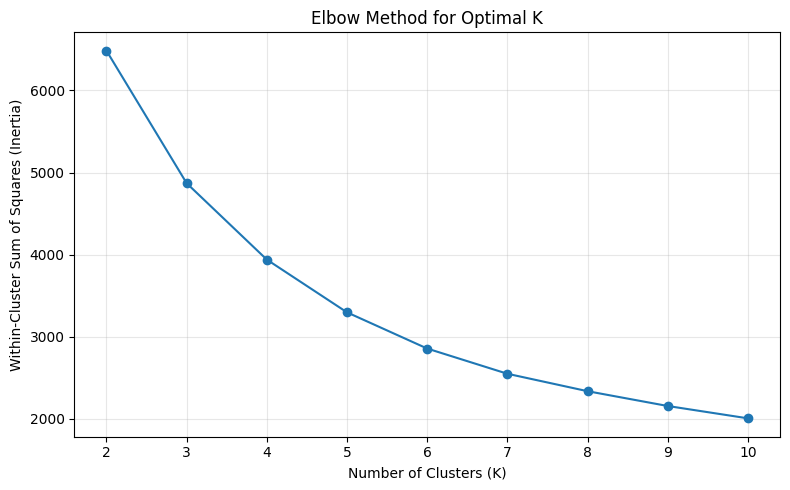

In [17]:
inertia = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(rfm_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Select K after inspecting the elbow plot.
optimal_k = 4

10. APPLY K-MEANS CLUSTERING

In [18]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Add cluster labels to customer statistics
customer_stats["Cluster"] = rfm["Cluster"]

print("\nCluster Assignment (first 10 customers):")
print(rfm.head(10))


Cluster Assignment (first 10 customers):
            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346           326          1  77183.60        3
12347             2          7   4310.00        0
12348            75          4   1797.24        3
12349            19          1   1757.55        2
12350           310          1    334.40        1
12352            36          8   2506.04        3
12353           204          1     89.00        1
12354           232          1   1079.40        1
12355           214          1    459.40        1
12356            23          3   2811.43        3


11. VISUALISE CLUSTERS: SCATTER PLOTS

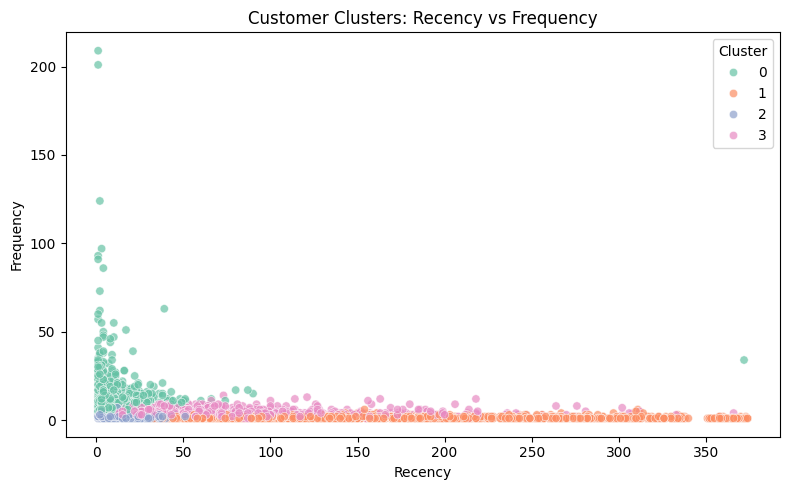

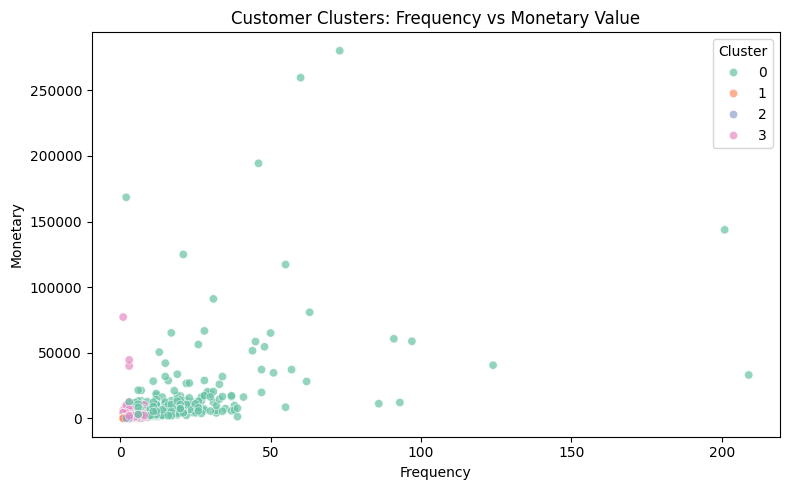

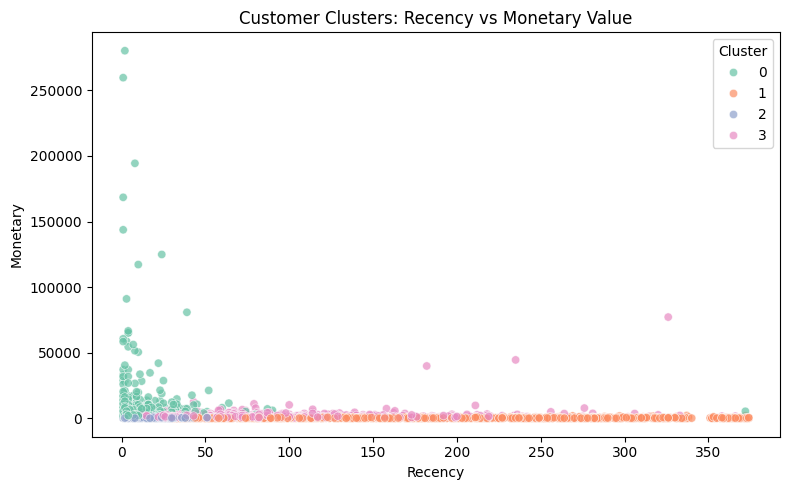

In [19]:
# Plot 1: Recency vs Frequency
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)
plt.title("Customer Clusters: Recency vs Frequency")
plt.tight_layout()
plt.show()

# Plot 2: Frequency vs Monetary Value
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)
plt.title("Customer Clusters: Frequency vs Monetary Value")
plt.tight_layout()
plt.show()

# Plot 3: Recency vs Monetary Value
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)
plt.title("Customer Clusters: Recency vs Monetary Value")
plt.tight_layout()
plt.show()

12. PROFILE EACH CLUSTER

In [20]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "size"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
).round(2)

# Include average purchase value and lifetime spending proxy
extra_profile = customer_stats.groupby("Cluster").agg(
    Average_Purchase_Value=("Average_Purchase_Value", "mean"),
    Average_Lifetime_Value=("Customer_Lifetime_Value", "mean")
).round(2)

cluster_profile = cluster_profile.join(extra_profile)

print("\nCustomer Cluster Profiles:")
print(cluster_profile)



Customer Cluster Profiles:
         Customer_Count  Average_Recency  Average_Frequency  Average_Monetary  \
Cluster                                                                         
0                   713            12.17              13.75           8088.02   
1                  1622           181.51               1.32            341.00   
2                   837            17.70               2.19            557.32   
3                  1166            71.64               4.08           1801.78   

         Average_Purchase_Value  Average_Lifetime_Value  
Cluster                                                  
0                        623.81                 8088.02  
1                        282.45                  341.00  
2                        278.28                  557.32  
3                        579.69                 1801.78  


13. BAR CHART: NUMBER OF CUSTOMERS PER CLUSTER:

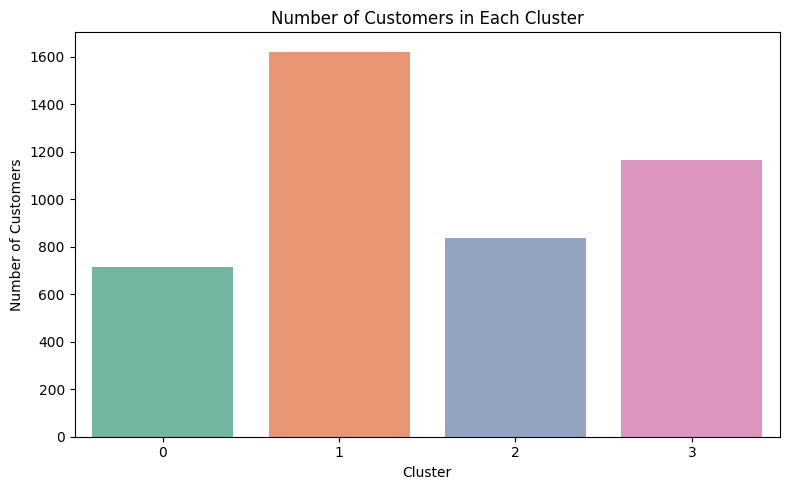

In [21]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values,
    hue=cluster_counts.index.astype(str),
    legend=False,
    palette="Set2"
)
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

14. INSIGHTS AND MARKETING RECOMMENDATIONS

In [22]:
overall_recency = rfm["Recency"].median()
overall_frequency = rfm["Frequency"].median()
overall_monetary = rfm["Monetary"].median()

print("\nCLUSTER INSIGHTS AND MARKETING STRATEGIES")
print("=" * 55)

for cluster_id, row in cluster_profile.iterrows():

    recency = row["Average_Recency"]
    frequency = row["Average_Frequency"]
    monetary = row["Average_Monetary"]

    print(f"\nCluster {cluster_id}")
    print(f"Number of Customers: {int(row['Customer_Count'])}")
    print(f"Average Recency: {recency:.2f} days")
    print(f"Average Purchase Frequency: {frequency:.2f}")
    print(f"Average Monetary Value: {monetary:.2f}")

    if (
        recency <= overall_recency
        and frequency >= overall_frequency
        and monetary >= overall_monetary
    ):
        print("Customer Type: High-value loyal customers")
        print("Marketing Action: Offer loyalty rewards, exclusive deals "
              "and personalised recommendations.")

    elif (
        recency > overall_recency
        and frequency < overall_frequency
    ):
        print("Customer Type: At-risk or inactive customers")
        print("Marketing Action: Send win-back campaigns, reminders "
              "and targeted re-engagement offers.")

    elif (
        frequency < overall_frequency
        and monetary >= overall_monetary
    ):
        print("Customer Type: High-spending, occasional customers")
        print("Marketing Action: Encourage repeat purchases through "
              "bundles, follow-up offers and loyalty incentives.")

    elif (
        recency <= overall_recency
        and frequency < overall_frequency
    ):
        print("Customer Type: Recent or developing customers")
        print("Marketing Action: Use welcome offers, product suggestions "
              "and campaigns that encourage a second purchase.")

    else:
        print("Customer Type: Regular or lower-value customers")
        print("Marketing Action: Use relevant promotions, cross-selling "
              "and product recommendations.")


CLUSTER INSIGHTS AND MARKETING STRATEGIES

Cluster 0
Number of Customers: 713
Average Recency: 12.17 days
Average Purchase Frequency: 13.75
Average Monetary Value: 8088.02
Customer Type: High-value loyal customers
Marketing Action: Offer loyalty rewards, exclusive deals and personalised recommendations.

Cluster 1
Number of Customers: 1622
Average Recency: 181.51 days
Average Purchase Frequency: 1.32
Average Monetary Value: 341.00
Customer Type: At-risk or inactive customers
Marketing Action: Send win-back campaigns, reminders and targeted re-engagement offers.

Cluster 2
Number of Customers: 837
Average Recency: 17.70 days
Average Purchase Frequency: 2.19
Average Monetary Value: 557.32
Customer Type: Regular or lower-value customers
Marketing Action: Use relevant promotions, cross-selling and product recommendations.

Cluster 3
Number of Customers: 1166
Average Recency: 71.64 days
Average Purchase Frequency: 4.08
Average Monetary Value: 1801.78
Customer Type: Regular or lower-value c

15. FINAL SUMMARY

In [23]:
print("\nFINAL SUMMARY")
print("-" * 55)
print("Total Customers Analysed:", len(rfm))
print("Number of Clusters:", optimal_k)
print("Clustering Algorithm: K-Means")
print("Selected Features: Recency, Frequency, Monetary Value")
print("Scaling Method: StandardScaler")
print("Cluster Sizes:")
print(cluster_counts)

# Save customer segmentation results
rfm.to_csv("customer_segmentation_results.csv", index=True)

print("\nResults saved to customer_segmentation_results.csv")


FINAL SUMMARY
-------------------------------------------------------
Total Customers Analysed: 4338
Number of Clusters: 4
Clustering Algorithm: K-Means
Selected Features: Recency, Frequency, Monetary Value
Scaling Method: StandardScaler
Cluster Sizes:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64

Results saved to customer_segmentation_results.csv
